# Omsorgstjenester — hjemmetjenestebrukere med omfattende bistandsbehov

Table **12292** (*Omsorgstjenester – supplerende grunnlagstall*, 2015–2025)
through the `ssb_statistikkbanken` wrapper: **search → describe → values →
fetch → plot**, with no manual cleanup in between.

The chart at the end shows *Hjemmetjenestebrukere, omfattende bistandsbehov,
67 år og over* for every available year, stacked by its two age bands.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from ssb_statistikkbanken import SSB

pd.set_option("display.max_colwidth", 95)

ssb = SSB()
ssb

SSB(language='no', timeout=30, max_workers=4, cache=True)

## 1 · Find the table — `ssb.search()`

**What it does:** free-text query across SSB's ~3,800 tables, returning a
DataFrame rather than a printout — so you can filter, sort and subset the search
results themselves.

**Why a DataFrame matters:** you rarely know the table id up front. Getting
results as data means you can narrow with ordinary pandas (`.loc`, `str.contains`)
instead of squinting at console output.

⚠️ It also matches **value labels**, not just titles, so a hit can be unrelated
to your query — always read the `label` column before trusting one.

In [2]:
hits = ssb.search("omsorgstjenester", limit=25)
hits.loc[hits["id"] == "12292", ["id", "label", "firstPeriod", "lastPeriod", "updated"]]

/tmp/ipykernel_8906/3880246496.py:1: UserWarning: 90 tables matched but only 25 are shown. Raise limit= or narrow the query.
  hits = ssb.search("omsorgstjenester", limit=25)


,id,label,firstPeriod,lastPeriod,updated
0,12292,12292: Omsorgstjenester - supplerende grunnlagstall (K) 2015-2025,2015,2025,2026-06-15T06:00:00Z


## 2 · What's inside it — `ssb.describe()` and `ssb.variables()`

**`describe(id)`** returns a `TableInfo` that renders as a card in Jupyter. It is
*data*, not a printout — `info["ContentsCode"].codes` works, and it's cached, so
later calls in this notebook cost nothing.

**`variables(id)`** is the same metadata as one row per dimension. The column to
watch is **`mandatory`**: SSB rejects a query that omits a mandatory variable
with a `400`. The wrapper fills those in for you (`*` for most, the latest period
for time), which is why the fetch below can name just one region and still work.

In [3]:
info = ssb.describe("12292")
info

variable,label,values,mandatory,examples
KOKkommuneregion0000,region,891,yes,3101: Halden; 3103: Moss; 3105: Sarpsborg; 3107: Fredrikstad; … (+887)
ContentsCode,statistikkvariabel,49,yes,KOSaarsverkvg0000: Brukerrettede årsverk med videregående helsefaglig utdanning i omsorgstjenesten (antall); KOSaarsverkuniho0000: Brukerrettede årsverk med høyere helsefaglig utdanning i omsorgstjenesten (antall); KOSomsorgbrukere0000: Brukere av utvalgte omsorgstjenester (antall); KOSinst80aarover0000: Institusjon - beboere 80 år og over (antall); … (+45)
Tid,år,11,yes,2015: 2015; 2016: 2016; 2017: 2017; 2018: 2018; … (+7)


In [4]:
ssb.variables("12292")

,variable,label,n_values,mandatory,code_lists,example_values
0,KOKkommuneregion0000,region,891,True,"agg_KOGkommuneregion000005400, agg_KOGkommuneregion000005401, agg_KOGkommuneregion000005402...",3101: Halden; 3103: Moss; 3105: Sarpsborg; …
1,ContentsCode,statistikkvariabel,49,True,,KOSaarsverkvg0000: Brukerrettede årsverk med videregående helsefaglig utdanning i omsorgstj...
2,Tid,år,11,True,,2015: 2015; 2016: 2016; 2017: 2017; …


Three dimensions, all mandatory — 891 regions, 49 statistics and 11 years. The
region list runs from individual kommuner up to national aggregates.

## 3 · Locate the statistic — `ssb.values()`

**What it does:** lists every value code of a variable — the exact strings you
pass to `fetch()`. Nothing is truncated.

**Why `search=`:** 891 regions and 49 statistics are unusable as a raw list.
`search=` filters on **code or label**, case-insensitively, so you can go from a
vague idea ("something about bistandsbehov") to a precise code in one step.

This is the step that replaces guessing. Codes like `KOShjelptkjerne60000` are
not discoverable any other way.

In [5]:
ssb.values("12292", "ContentsCode", search="omfattende bistandsbehov")

,variable,code,label,index
0,ContentsCode,KOSallesvaerthje0000,Brukere med omfattende bistandsbehov (antall),20
1,ContentsCode,KOSinstsvhjelpet0000,Institusjon - beboere med omfattende bistandsbehov (antall),21
2,ContentsCode,KOSkorttidsvhjel0000,"Institusjon - beboere på tidsbegr. opphold, omfattende bistandsbehov (antall)",22
3,ContentsCode,KOSlangtidsvhjel0000,"Institusjon - beboere på langtidsopphold, omfattende bistandsbehov (antall)",23
4,ContentsCode,KOShjelptkjernet0000,"Hjemmetjenestebrukere, omfattende bistandsbehov, i alt (antall)",24
5,ContentsCode,KOShjelptkjerne00000,"Hjemmetjenestebrukere, omfattende bistandsbehov, 0-66 år (antall)",25
6,ContentsCode,KOShjelptkjerne60001,"Hjemmetjenestebrukere, omfattende bistandsbehov, 67-79 år (antall)",26
7,ContentsCode,KOShjelptkjerne60000,"Hjemmetjenestebrukere, omfattende bistandsbehov, 67 år og over (antall)",27
8,ContentsCode,KOShjelptkjerne80000,"Hjemmetjenestebrukere, omfattende bistandsbehov 80 år og over (antall)",28


The one asked for is **`KOShjelptkjerne60000`** — *67 år og over*. Note it sits
alongside its two components, `67-79 år` and `80 år og over`, which is what makes
a stacked chart meaningful rather than decorative.

The national aggregate region is `EAK` (*Landet*):

In [6]:
ssb.values("12292", "KOKkommuneregion0000", search="landet")

,variable,code,label,index
0,KOKkommuneregion0000,3419,Våler (Innlandet),137
1,KOKkommuneregion0000,5046,Høylandet,607
2,KOKkommuneregion0000,1743,Høylandet (-2017),663
3,KOKkommuneregion0000,EAK,Landet,839
4,KOKkommuneregion0000,EAKUO,Landet uten Oslo,840
5,KOKkommuneregion0000,EKA34,Innlandet,847


## 4 · Fetch — `ssb.fetch()`

One call for three statistics, the national total, every year.

**Reading the arguments:**

- `KOKkommuneregion0000="EAK"` — filters are keyword arguments named after the
  variable. Values can be a single code, a list, a `range`, or a wildcard.
- `contents=[...]` — a friendly alias for `ContentsCode`, so you don't have to
  remember SSB's internal name.
- `time="*"` — every period. The wrapper expands `*` **locally** against the
  metadata, so it knows the exact cell count before sending and can split the
  request if it would exceed SSB's 800,000-cell limit. A PxWeb expression like
  `"top(5)"` cannot be counted that way, which is why explicit selections are
  preferred for anything large.
- The `Tid` variable is mandatory but unmentioned — `time=` covers it.

In [7]:
STATS = {
    "KOShjelptkjerne60001": "67-79 år",
    "KOShjelptkjerne80000": "80 år og over",
    "KOShjelptkjerne60000": "67 år og over (total)",
}

df = ssb.fetch(
    "12292",
    KOKkommuneregion0000="EAK",
    contents=list(STATS),
    time="*",
)
df.head()

,KOKkommuneregion0000,KOKkommuneregion0000_code,ContentsCode,ContentsCode_code,Tid,Tid_code,year,value
0,Landet,EAK,"Hjemmetjenestebrukere, omfattende bistandsbehov, 67-79 år (antall)",KOShjelptkjerne60001,2015,2015,2015,4934
1,Landet,EAK,"Hjemmetjenestebrukere, omfattende bistandsbehov, 67-79 år (antall)",KOShjelptkjerne60001,2016,2016,2016,5255
2,Landet,EAK,"Hjemmetjenestebrukere, omfattende bistandsbehov, 67-79 år (antall)",KOShjelptkjerne60001,2017,2017,2017,5500
3,Landet,EAK,"Hjemmetjenestebrukere, omfattende bistandsbehov, 67-79 år (antall)",KOShjelptkjerne60001,2018,2018,2018,5754
4,Landet,EAK,"Hjemmetjenestebrukere, omfattende bistandsbehov, 67-79 år (antall)",KOShjelptkjerne60001,2019,2019,2019,5966


In [8]:
print(df.dtypes.to_string())
print(f"\nrows: {len(df)}   years: {df['year'].min()}-{df['year'].max()}")

KOKkommuneregion0000           str
KOKkommuneregion0000_code      str
ContentsCode                   str
ContentsCode_code              str
Tid                            str
Tid_code                       str
year                         Int16
value                        Int64

rows: 33   years: 2015-2025


Tidy long, already typed — `value` a nullable `Int64`, `year` an `Int16` derived
from the period codes, and every dimension split into a label column plus a
`_code` sibling. No `.iloc` trimming, no string splitting.

**Why long and not wide?** One row per observation is the shape that filters,
groups and joins cleanly — it's what you want for `groupby`, for merging against
KLASS, and for writing to a database. Wide is a *presentation* shape, so the
wrapper hands you long and lets you pivot when you actually need to.

## 5 · Reshape to wide — `.to_wide()`

**Why not just `df.pivot_table(...)`?** Because pandas sorts the new columns
**alphabetically**, and that quietly destroys meaningful order. On 05810's age
bands, plain `pivot_table` yields:

```
0-6 år, 16-44 år, 45-66 år, 67-79 år, 7-15 år, 80 år eller eldre, Alle
                                      ^^^^^^^ text-sorted between 67-79 and 80+
```

`"7-15 år"` lands between `"67-79 år"` and `"80 år eller eldre"` because it's
comparing strings, and the `Alle` total drifts to the end. A chart built on that
is wrong in a way that's easy to miss.

SSB publishes the intended order in its metadata (`category.index`), and
`to_wide()` puts it back on **both** axes. It also picks sensible defaults —
time down the side, the widest other dimension across the top — and reads
`values="value"` for you.

`.to_wide()` lives on `dataset()` rather than `fetch()`, alongside `.to_pandas()`,
`.to_polars()` and `.to_records()`, because it's another *output shape* of the
same query.

In [9]:
wide = (
    ssb.dataset(
        "12292",
        KOKkommuneregion0000="EAK",
        contents=list(STATS),
        time="*",
    )
    .to_wide(columns="ContentsCode_code")
    .rename(columns=STATS)
)
wide

ContentsCode_code,67-79 år,67 år og over (total),80 år og over
year,,,
2015,4934,13865,8931
2016,5255,14539,9284
2017,5500,15066,9566
2018,5754,15608,9854
2019,5966,15897,9931
2020,6312,16518,10206
2021,6654,17224,10570
2022,6756,17120,10364
2023,7190,17734,10544


Columns came back in SSB's own publication order (67-79, then 67+, then 80+),
not alphabetically — that's `to_wide()` doing its job.

### Sanity-check before charting

The two age bands should add up to the reported 67+ total. Worth verifying rather
than assuming — if it didn't hold, the stacked chart would be quietly lying about
what the bar heights mean.

In [10]:
wide["sum of bands"] = wide["67-79 år"] + wide["80 år og over"]
wide[["67-79 år", "80 år og over", "67 år og over (total)", "sum of bands"]]

ContentsCode_code,67-79 år,80 år og over,67 år og over (total),sum of bands
year,,,,
2015,4934,8931,13865,13865
2016,5255,9284,14539,14539
2017,5500,9566,15066,15066
2018,5754,9854,15608,15608
2019,5966,9931,15897,15897
2020,6312,10206,16518,16518
2021,6654,10570,17224,17224
2022,6756,10364,17120,17120
2023,7190,10544,17734,17734


In [11]:
matches = (wide["sum of bands"] == wide["67 år og over (total)"]).all()
print(f"bands sum to the reported total in every year: {matches}")

bands sum to the reported total in every year: True


Exact in all 11 years, so the stack is a true decomposition of the requested
figure — the bar tops *are* the 67+ total.

## 6 · Stacked bar chart

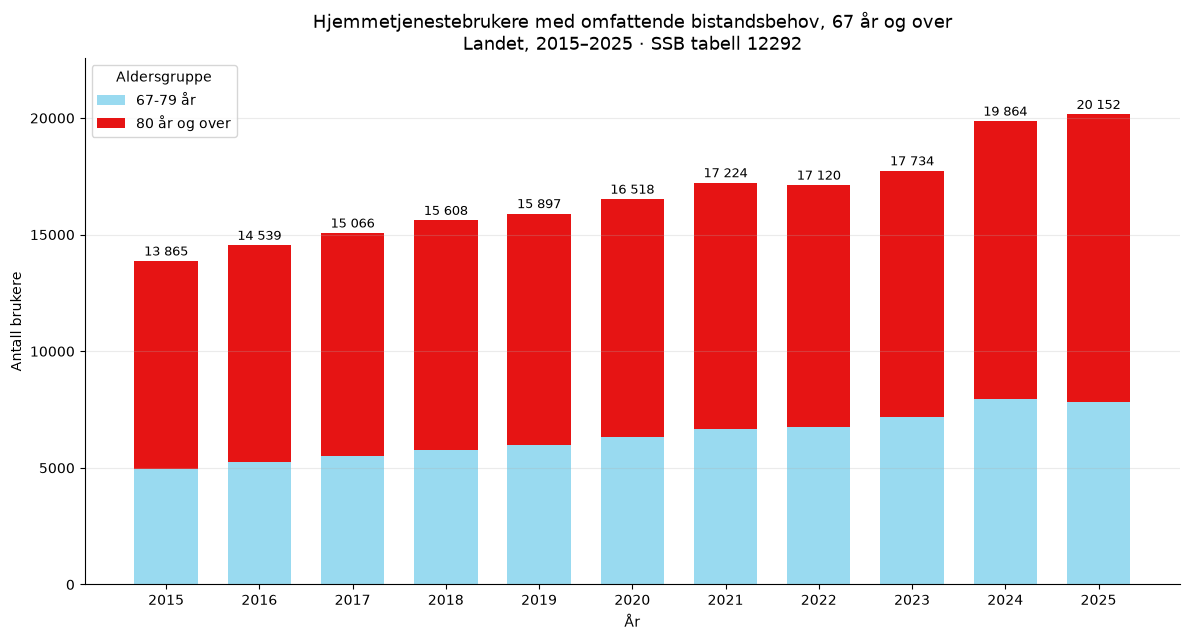

In [12]:
bands = wide[["67-79 år", "80 år og over"]].astype(float)
colors = ["#99daf0", "#e61414"]

fig, ax = plt.subplots(figsize=(12, 6.5))
bottom = None
for (band, values), color in zip(bands.items(), colors, strict=True):
    ax.bar(bands.index, values, width=0.68, label=band, bottom=bottom, color=color)
    bottom = values if bottom is None else bottom + values

totals = wide["67 år og over (total)"].astype(float)
for year, total in totals.items():
    ax.annotate(
        f"{int(total):,}".replace(",", " "),
        (year, total),
        textcoords="offset points",
        xytext=(0, 4),
        ha="center",
        fontsize=9,
    )

ax.set_title(
    "Hjemmetjenestebrukere med omfattende bistandsbehov, 67 år og over\n"
    f"Landet, {bands.index.min()}–{bands.index.max()} · SSB tabell 12292",
    fontsize=13,
)
ax.set_xlabel("År")
ax.set_ylabel("Antall brukere")
ax.set_xticks(list(bands.index))
ax.set_ylim(0, totals.max() * 1.12)
ax.legend(title="Aldersgruppe", loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Growth from **13 865** in 2015 to **20 152** in 2025 — about +45%. Splitting the
bars shows the 67–79 band growing faster in relative terms (+59%) than the 80+
band (+38%), which the headline total alone would hide.

In [13]:
growth = (wide.iloc[-1] / wide.iloc[0] - 1).mul(100).round(1)
growth.name = f"% change {wide.index.min()}-{wide.index.max()}"
growth.drop("sum of bands").to_frame()

,% change 2015-2025
ContentsCode_code,
67-79 år,58.6
67 år og over (total),45.3
80 år og over,38.0


---

Reference: [`src/README.md`](../src/README.md) ·
tour notebook: [`ssb_dataframe_fetcher_tool.ipynb`](ssb_dataframe_fetcher_tool.ipynb)